In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../DATA/bank-full.csv", sep=';')

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [5]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

<Axes: xlabel='y', ylabel='count'>

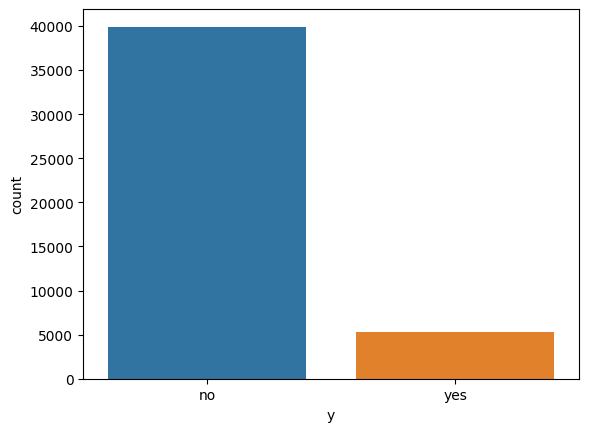

In [6]:
sns.countplot(x='y', data=df, hue='y')

In [7]:
df['y'] = df['y'].map({'yes':1, 'no':0})

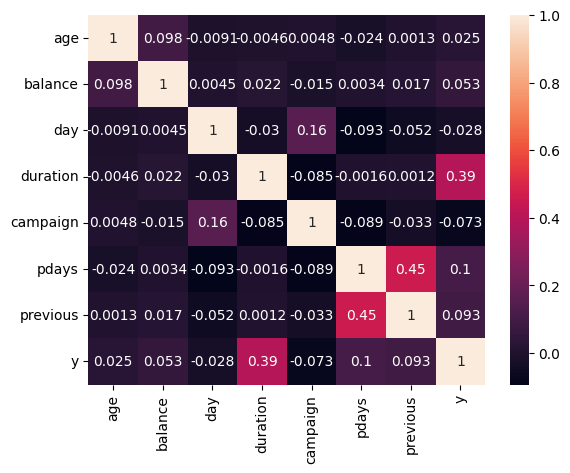

In [8]:
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [11]:
df = df.drop('duration', axis=1)

In [12]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import SimpleImputer, KNNImputer

In [14]:
X = df.drop('y', axis=1)

In [15]:
y = df['y']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=104, stratify=y)

In [17]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [18]:
num_features

['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

In [19]:
cat_features

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome']

In [20]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [21]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transformer, cat_features),
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [23]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model',  LogisticRegressionCV(Cs=5,
                                   cv=5,
                                  penalty='l2',
                                  solver='lbfgs',
                                  max_iter=1_000,
                                  n_jobs=-1,
                                  random_state=104,
                                   class_weight='balanced'))
])

In [24]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [25]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [26]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [27]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [1.]


In [28]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [29]:
accuracy

0.7545333923042902

In [30]:
recall

0.5765595463137996

In [31]:
precision

0.25608732157850544

In [32]:
roc_auc_test

0.7475009432859111

In [33]:
roc_auc_train

0.7713253215784353

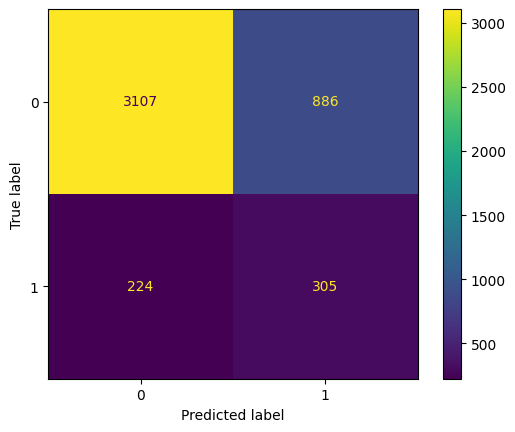

In [34]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test)

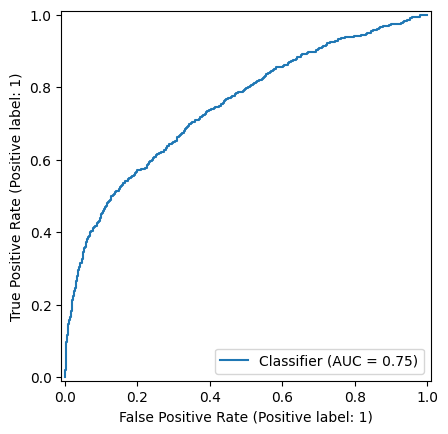

In [35]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba)

In [36]:
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [37]:
y_full_proba = pipe.predict_proba(X)[:, 1]

In [53]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")
print(f"Лучшее значение l1_ratio: {best_final_model.l1_ratio_}")

Лучшее значение C: [0.0001]
Лучшее значение l1_ratio: [None]


In [39]:
roc_auc_full = roc_auc_score(y, y_full_proba)

In [40]:
roc_auc_full

0.7302143178062792

In [41]:
correct_bank_data = {
    'age': [22, 45],
    'job': ['blue-collar', 'management'],
    'marital': ['single', 'married'],
    'education': ['secondary', 'tertiary'],
    'default': ['no', 'no'],
    'balance': [5, 5400],             
    'housing': ['yes', 'no'],
    'loan': ['yes', 'no'],
    'contact': ['unknown', 'cellular'],
    'day': [18, 10],
    'month': ['may', 'nov'],
    'campaign': [6, 1],
    'pdays': [-1, 90],
    'previous': [0, 3],
    'poutcome': ['unknown', 'success']
}

In [42]:
test_df_bank = pd.DataFrame(correct_bank_data)

In [43]:
test_df_bank

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
0,22,blue-collar,single,secondary,no,5,yes,yes,unknown,18,may,6,-1,0,unknown
1,45,management,married,tertiary,no,5400,no,no,cellular,10,nov,1,90,3,success


In [44]:
predictions = pipe.predict(test_df_bank)
probabilities = pipe.predict_proba(test_df_bank)

In [45]:
class_labels = {0: 'Отказ (no)', 1: 'Согласие / Открытие вклада (yes)'}

print("="*65)
print("🦾 ВЕРДИКТ МОДЕЛИ:")
print("="*65)

for i in range(2):
    pred_class = predictions[i]
    print(f"Клиент №{i+1}:")
    print(f"  -> Предсказание модели: Класс {pred_class} ({class_labels[pred_class]})")
    print(f"  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:")
    print(f"                     {np.round(probabilities[i][0], 4) * 100}%      |    {np.round(probabilities[i][1], 4) * 100}%")
    print("-"*65)

🦾 ВЕРДИКТ МОДЕЛИ:
Клиент №1:
  -> Предсказание модели: Класс 0 (Отказ (no))
  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:
                     70.08%      |    29.92%
-----------------------------------------------------------------
Клиент №2:
  -> Предсказание модели: Класс 1 (Согласие / Открытие вклада (yes))
  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:
                     32.72%      |    67.28%
-----------------------------------------------------------------


In [46]:
class_percents = df['y'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 88.3%, 1: 11.7%


In [47]:
import json
import os

advanced_report = {
    "project": "Bank Deposit Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [48]:
from joblib import dump, load

In [49]:
dump(pipe, "model/bank_deposit_predict_logistic_regression_cv_2026_v1.pkl")

['model/bank_deposit_predict_logistic_regression_cv_2026_v1.pkl']

In [50]:
loaded_pipe = load("model/bank_deposit_predict_logistic_regression_cv_2026_v1.pkl")

In [51]:
predictions = loaded_pipe.predict(test_df_bank)
probabilities = loaded_pipe.predict_proba(test_df_bank)

In [52]:
class_labels = {0: 'Отказ (no)', 1: 'Согласие / Открытие вклада (yes)'}

print("="*65)
print("🦾 ВЕРДИКТ МОДЕЛИ:")
print("="*65)

for i in range(2):
    pred_class = predictions[i]
    print(f"Клиент №{i+1}:")
    print(f"  -> Предсказание модели: Класс {pred_class} ({class_labels[pred_class]})")
    print(f"  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:")
    print(f"     {np.round(probabilities[i][0], 4) * 100}% ; {np.round(probabilities[i][1], 4) * 100}%")
    print("-"*65)

🦾 ВЕРДИКТ МОДЕЛИ:
Клиент №1:
  -> Предсказание модели: Класс 0 (Отказ (no))
  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:
     70.08% ; 29.92%
-----------------------------------------------------------------
Клиент №2:
  -> Предсказание модели: Класс 1 (Согласие / Открытие вклада (yes))
  -> Вероятности [Класс 0 (Отказ), Класс 1 (Вклад)]:
     32.72% ; 67.28%
-----------------------------------------------------------------
